# Лабораторная работа №2. Виртуальный датчик концентрации продукта обжига

**Выполнил:** Смирнов Константин Андреевич, М8О-202СВ-25

Нужно по минутной телеметрии печи оценивать концентрацию выходного продукта в текущий момент. Лаборатория выдаёт результат замера через 10-15 минут после отбора пробы, поэтому оператор видит фактическое значение с запаздыванием и нерегулярно. Виртуальный датчик должен дать оценку сразу, опираясь только на те данные, которые уже есть на пульте.

Данные лежат рядом с ноутбуком: `data_train.csv`, `target_train.csv` для обучения и `data_test_small.csv`, `target_test_small.csv` для контроля.


In [1]:
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats
from sklearn.base import clone
from sklearn.decomposition import PCA
from sklearn.ensemble import ExtraTreesRegressor, HistGradientBoostingRegressor
from sklearn.inspection import permutation_importance
from sklearn.linear_model import RidgeCV
from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.model_selection import TimeSeriesSplit
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from statsmodels.stats.diagnostic import acorr_ljungbox, het_breuschpagan
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.stattools import acf, adfuller

warnings.filterwarnings("ignore")
plt.rcParams["figure.figsize"] = (13, 4.5)
plt.rcParams["axes.grid"] = True
pd.set_option("display.width", 170)
pd.set_option("display.max_columns", 40)

DATA_DIR = Path(".")
SEED = 42
LAB_DELAY_MIN = 15  # запасное значение, ниже задержка выбирается по данным

telemetry_train = pd.read_csv(DATA_DIR / "data_train.csv", parse_dates=["datetime"])
telemetry_test = pd.read_csv(DATA_DIR / "data_test_small.csv", parse_dates=["datetime"])
target_train = pd.read_csv(DATA_DIR / "target_train.csv", parse_dates=["Дата"]).rename(columns={"Дата": "datetime"})
target_test = pd.read_csv(DATA_DIR / "target_test_small.csv", parse_dates=["Дата"]).rename(columns={"Дата": "datetime"})
target_all = pd.concat([target_train, target_test], ignore_index=True).sort_values("datetime")

print("телеметрия, train/test:", telemetry_train.shape, telemetry_test.shape)
print("замеры, train/test:", target_train.shape, target_test.shape)
print("телеметрия train:", telemetry_train["datetime"].min(), "-", telemetry_train["datetime"].max())
print("телеметрия test: ", telemetry_test["datetime"].min(), "-", telemetry_test["datetime"].max())


телеметрия, train/test: (319546, 17) (39943, 17)
замеры, train/test: (1773, 2) (318, 2)
телеметрия train: 2019-03-01 00:01:00 - 2019-10-07 19:58:00
телеметрия test:  2019-10-07 19:59:00 - 2019-11-04 10:25:00


## 1. Разведочный анализ

Сначала смотрю, что вообще есть в телеметрии: заполненность каналов, характер сигналов, выбросы. Отдельно разбираю лабораторные замеры, потому что именно из-за их нерегулярности задача нетривиальна.


,missing_pct
telemetry_12,99.34
telemetry_13,99.34
telemetry_14,99.34
telemetry_15,99.34
telemetry_4,0.04
telemetry_0,0.01
telemetry_5,0.01
telemetry_1,0.01
telemetry_2,0.01
telemetry_3,0.01


каналы без данных: telemetry_12, telemetry_13, telemetry_14, telemetry_15
остаётся каналов: 12


,mean,std,min,max
telemetry_4,0.762,0.326,0.000,1.000
telemetry_0,0.610,0.276,0.003,1.000
telemetry_5,0.696,0.284,0.000,1.000
telemetry_1,0.380,0.198,0.000,0.611
telemetry_2,0.267,0.088,0.032,1.000
telemetry_3,0.520,0.259,0.000,1.000
telemetry_6,0.594,0.300,0.000,1.000
telemetry_7,0.523,0.253,0.021,1.000
telemetry_8,0.470,0.024,0.344,1.000
telemetry_9,0.536,0.255,0.000,1.000


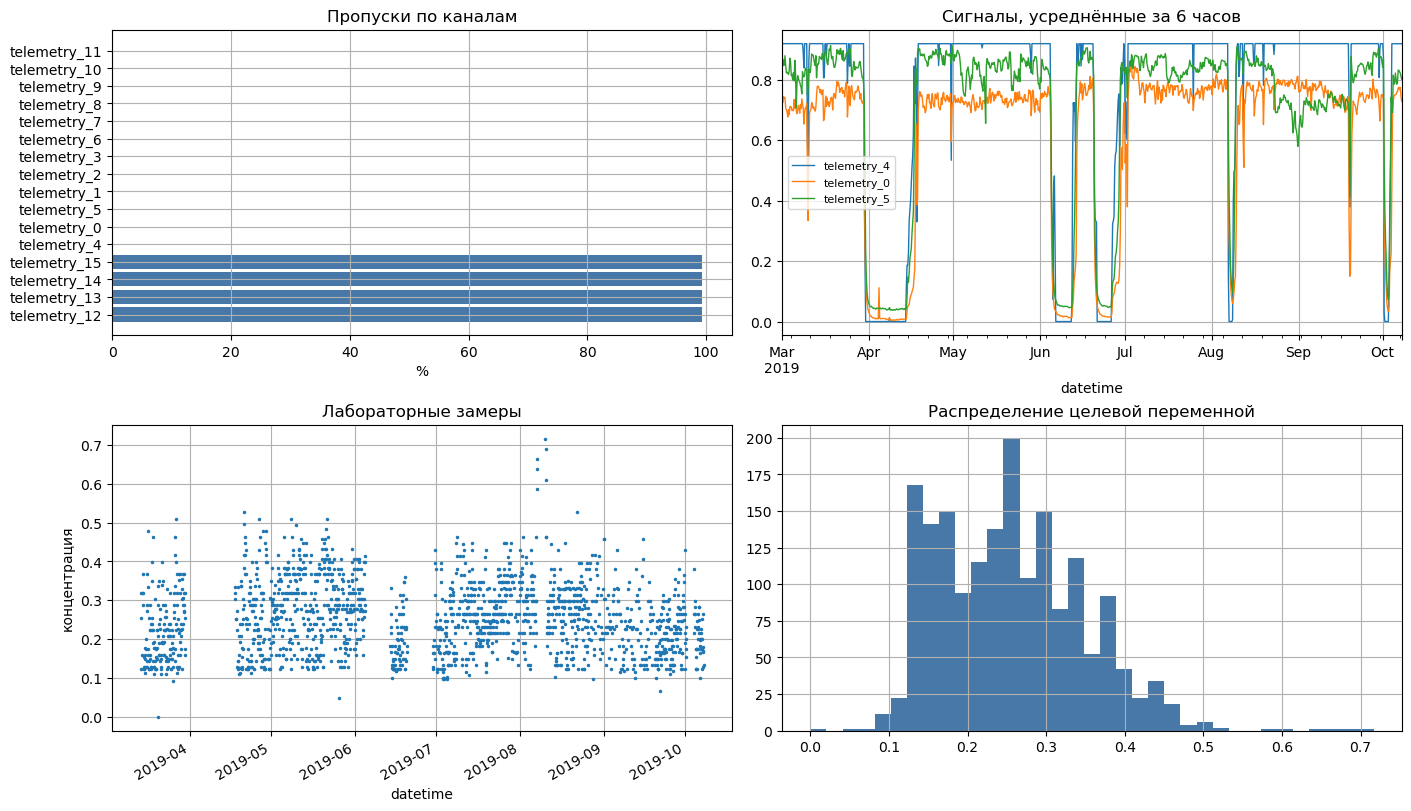

In [2]:
signal_columns = [c for c in telemetry_train.columns if c != "datetime"]
missing_share = telemetry_train[signal_columns].isna().mean().sort_values(ascending=False)
active_columns = missing_share[missing_share < 0.5].index.tolist()
silent_columns = missing_share[missing_share >= 0.5].index.tolist()

display((100 * missing_share).round(2).to_frame("missing_pct"))
print("каналы без данных:", ", ".join(silent_columns))
print("остаётся каналов:", len(active_columns))
display(telemetry_train[active_columns].describe().T[["mean", "std", "min", "max"]].round(3))

fig, axes = plt.subplots(2, 2, figsize=(14, 8), constrained_layout=True)
axes[0, 0].barh(missing_share.index, 100 * missing_share.values, color="#4878a8")
axes[0, 0].set_title("Пропуски по каналам")
axes[0, 0].set_xlabel("%")
telemetry_train.set_index("datetime")[active_columns[:3]].resample("6h").mean().plot(ax=axes[0, 1], linewidth=1)
axes[0, 1].set_title("Сигналы, усреднённые за 6 часов")
axes[0, 1].legend(fontsize=8)
target_train.set_index("datetime")["target"].plot(ax=axes[1, 0], marker=".", markersize=3, linewidth=0)
axes[1, 0].set_title("Лабораторные замеры")
axes[1, 0].set_ylabel("концентрация")
axes[1, 1].hist(target_train["target"], bins=35, color="#4878a8")
axes[1, 1].set_title("Распределение целевой переменной")
plt.show()


In [3]:
q1 = telemetry_train[active_columns].quantile(.25)
q3 = telemetry_train[active_columns].quantile(.75)
spread = q3 - q1
is_outlier = (telemetry_train[active_columns] < q1 - 3 * spread) | (telemetry_train[active_columns] > q3 + 3 * spread)
saturated = (telemetry_train[active_columns] <= 0.001) | (telemetry_train[active_columns] >= 0.999)
display(pd.DataFrame({
    "выбросы по 3·IQR, %": 100 * is_outlier.mean(),
    "на границах шкалы, %": 100 * saturated.mean(),
}).round(2))
print("Каналы нормированы в 0..1 и заметную часть времени висят на границах диапазона,"
      " поэтому правило 3·IQR записывает в выбросы пятую часть точек. Это рабочие режимы,"
      " а не сбои датчиков, и вырезать их нельзя: вместе с ними уйдёт поведение печи на краях диапазона.")

# Пропуски закрываю последним известным значением (не дольше 15 минут), остатки медианой train.
# Линейная интерполяция здесь не подходит: она подтягивает значения из будущего,
# которого у оператора в момент прогноза ещё нет.
median_train = telemetry_train[active_columns].median()
telemetry = pd.concat(
    [telemetry_train[["datetime"] + active_columns], telemetry_test[["datetime"] + active_columns]],
    ignore_index=True,
).sort_values("datetime").reset_index(drop=True)
telemetry[active_columns] = telemetry[active_columns].astype("float32")
telemetry[active_columns] = telemetry[active_columns].ffill(limit=15).fillna(median_train)
print("осталось пропусков:", int(telemetry[active_columns].isna().sum().sum()))
print("строк телеметрии:", len(telemetry))


,"выбросы по 3·IQR, %","на границах шкалы, %"
telemetry_4,21.38,13.58
telemetry_0,20.28,0.02
telemetry_5,15.94,0.07
telemetry_1,21.42,20.74
telemetry_2,19.33,0.00
telemetry_3,19.85,19.68
telemetry_6,21.28,18.76
telemetry_7,20.87,15.84
telemetry_8,0.07,0.00
telemetry_9,0.00,2.75


Каналы нормированы в 0..1 и заметную часть времени висят на границах диапазона, поэтому правило 3·IQR записывает в выбросы пятую часть точек. Это рабочие режимы, а не сбои датчиков, и вырезать их нельзя: вместе с ними уйдёт поведение печи на краях диапазона.
осталось пропусков: 0
строк телеметрии: 359489


интервал между замерами, часы:


,count,mean,std,min,25%,50%,75%,max
datetime,1772.0,2.82,13.07,1.0,2.0,2.0,2.0,440.5


медиана 2.0 ч, максимум 440.5 ч, в сутки в среднем 12.0 замера


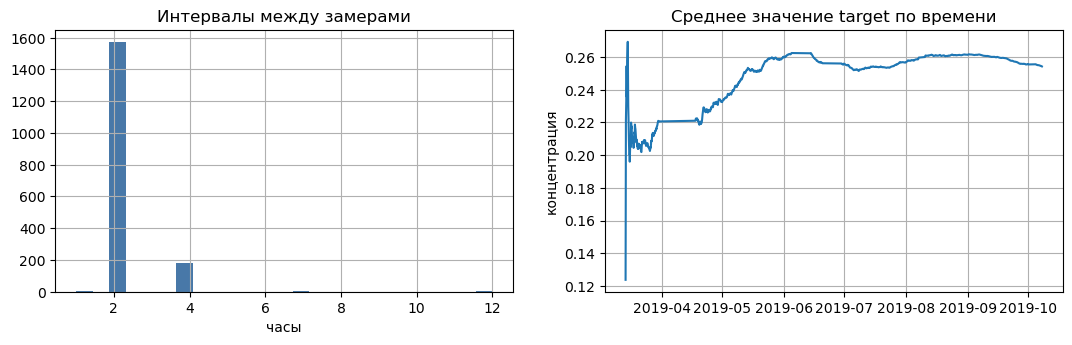

медиана target: 0.247 | размах: 0.0 - 0.716


In [4]:
lab_gap = target_train["datetime"].diff().dt.total_seconds().div(3600).dropna()
print("интервал между замерами, часы:")
display(lab_gap.describe().round(2).to_frame().T)
print(f"медиана {lab_gap.median():.1f} ч, максимум {lab_gap.max():.1f} ч, в сутки в среднем {24 / lab_gap.median():.1f} замера")

fig, axes = plt.subplots(1, 2, figsize=(13, 3.4))
axes[0].hist(lab_gap.clip(upper=12), bins=25, color="#4878a8")
axes[0].set_title("Интервалы между замерами")
axes[0].set_xlabel("часы")
axes[1].plot(target_train["datetime"], target_train["target"].expanding().mean(), linewidth=1.5)
axes[1].set_title("Среднее значение target по времени")
axes[1].set_ylabel("концентрация")
plt.show()
print("медиана target:", round(target_train["target"].median(), 3),
      "| размах:", round(target_train["target"].min(), 3), "-", round(target_train["target"].max(), 3))


,-0 мин,-10 мин,-20 мин,-30 мин,-45 мин,-60 мин
telemetry_4,-0.09,-0.08,-0.07,-0.09,-0.10,-0.09
telemetry_0,-0.19,-0.18,-0.18,-0.17,-0.16,-0.15
telemetry_5,-0.05,-0.07,-0.07,-0.07,-0.08,-0.08
telemetry_1,-0.04,-0.04,-0.03,-0.06,-0.05,-0.06
telemetry_2,-0.00,-0.01,-0.01,0.00,0.01,0.01
telemetry_3,-0.12,-0.12,-0.13,-0.18,-0.14,-0.16
telemetry_6,-0.08,-0.09,-0.08,-0.11,-0.11,-0.11
telemetry_7,-0.04,-0.05,-0.04,-0.04,-0.05,-0.03
telemetry_8,0.10,0.09,0.09,0.09,0.07,0.10
telemetry_9,-0.12,-0.12,-0.12,-0.12,-0.12,-0.12


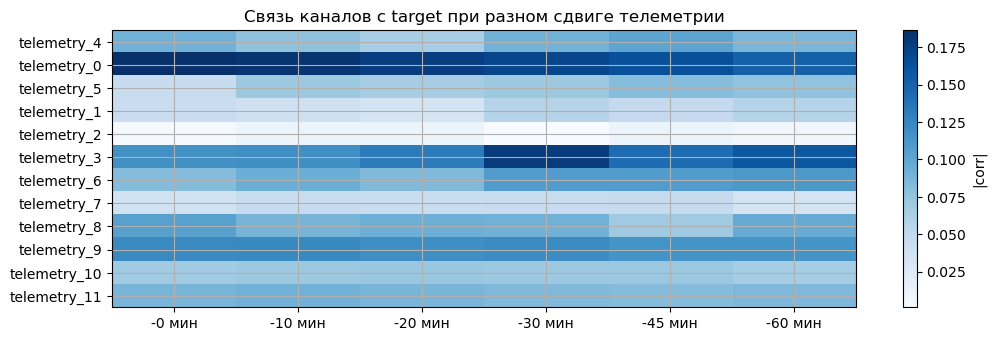

максимальная |корреляция|: 0.187


In [5]:
def lag_correlation_table(delays):
    rows = []
    for delay in delays:
        shifted = target_train.assign(probe_time=target_train["datetime"] - pd.Timedelta(minutes=delay))
        merged = pd.merge_asof(
            shifted.sort_values("probe_time"), telemetry,
            left_on="probe_time", right_on="datetime", direction="backward",
            tolerance=pd.Timedelta("1min"),
        ).dropna(subset=active_columns)
        corr = merged[active_columns + ["target"]].corr()["target"].drop("target")
        rows.append(pd.Series(corr, name=f"-{delay} мин"))
    return pd.DataFrame(rows)

lag_table = lag_correlation_table([0, 10, 20, 30, 45, 60])
display(lag_table.T.round(2))

plt.figure(figsize=(12, 3.6))
plt.imshow(lag_table.abs().T.to_numpy(), aspect="auto", cmap="Blues")
plt.colorbar(label="|corr|")
plt.yticks(range(len(active_columns)), active_columns)
plt.xticks(range(len(lag_table)), lag_table.index)
plt.title("Связь каналов с target при разном сдвиге телеметрии")
plt.show()
print("максимальная |корреляция|:", round(lag_table.abs().max().max(), 3))


Что видно из разведки:

* четыре канала `telemetry_12`–`telemetry_15` заполнены меньше чем на процент, датчики фактически отключены; в работе остаются 12 каналов, в них пропусков не больше 0.04%. Значения нормированы в 0–1, причём `telemetry_8` почти не двигается (стандартное отклонение 0.024);
* формальные выбросы по правилу трёх межквартильных размахов у восьми каналов из двенадцати — это примерно 20% точек, и почти все они стоят на границах шкалы 0 и 1. Это рабочие режимы, а не сбои измерения, поэтому данные оставлены как есть, а границы диапазона учитываются самими моделями на деревьях;
* лабораторных замеров 1773 за девять месяцев: медианный интервал 2 часа, но перерывы доходят до 18 суток, и всё это время оператор значения не знает;
* концентрация меняется в диапазоне 0–0.72 при медиане 0.247 и стандартном отклонении 0.092, то есть модель с ошибкой около 0.06 уже объясняет большую часть разброса;
* корреляции телеметрии с концентрацией слабые: максимум по модулю 0.19 у `telemetry_0`, у остальных каналов ещё меньше, и при сдвиге каналов на 10–60 минут картина почти не меняется. Значит, мгновенных значений мало: нужно описать динамику, иначе связи почти не видно.


## 2. Признаки

Раз связь проявляется с задержкой, для каждого канала строю описание его поведения:

* текущее значение и лаги 5, 15 и 60 минут;
* скользящие среднее, стандартное отклонение, минимум и максимум за 15 и 60 минут, плюс среднее за 240 минут;
* первую разность и относительную скорость изменения.

Скользящие статистики считаются по истории без текущей минуты (`shift(1)`): иначе в признак попадает значение той же минуты, и модель получает информацию, которой на пульте ещё нет. Дополнительно кодирую время суток синусом и косинусом с периодом 24 часа — режим печи связан со сменами.

Отдельная группа признаков — история лабораторных замеров: последнее известное значение, сколько часов прошло с этого замера и насколько каждый канал сдвинулся относительно своего состояния в момент того замера. Без этих признаков модель видит только форму кривой, но не знает, на каком уровне процесс находится сейчас.


In [6]:
def build_features(frame, columns):
    data = frame.set_index("datetime")[columns].astype("float32")
    parts = {}
    for col in columns:
        series = data[col]
        parts[col] = series
        for lag in (5, 15, 60):
            parts[f"{col}_lag{lag}"] = series.shift(lag)
        history = series.shift(1)
        for window in (15, 60):
            rolling = history.rolling(window, min_periods=window)
            for stat in ("mean", "std", "min", "max"):
                parts[f"{col}_{stat}{window}"] = getattr(rolling, stat)()
        parts[f"{col}_mean240"] = history.rolling(240, min_periods=200).mean()
        parts[f"{col}_diff"] = series.diff()
        parts[f"{col}_rate"] = (series.diff() / series.shift(1).abs().clip(lower=1e-3)).clip(-10, 10)
    result = pd.DataFrame(parts).astype("float32")
    result["hour_sin"] = np.sin(2 * np.pi * result.index.hour / 24).astype("float32")
    result["hour_cos"] = np.cos(2 * np.pi * result.index.hour / 24).astype("float32")
    return result.reset_index()

features = build_features(telemetry, active_columns)
feature_columns = [c for c in features.columns if c != "datetime"]
print(f"{len(active_columns)} каналов превратились в {len(feature_columns)} признаков")
print("матрица признаков:", features.shape)
display(features[feature_columns[:6]].describe().T[["mean", "std", "min", "max"]].round(3))


12 каналов превратились в 182 признаков
матрица признаков: (359489, 183)


,mean,std,min,max
telemetry_4,0.777,0.312,0.0,1.000
telemetry_4_lag5,0.777,0.312,0.0,1.000
telemetry_4_lag15,0.777,0.312,0.0,1.000
telemetry_4_lag60,0.777,0.312,0.0,1.000
telemetry_4_mean15,0.777,0.311,0.0,0.941
telemetry_4_std15,0.001,0.013,0.0,0.493


накопленная доля дисперсии: [0.727 0.867 0.918 0.943 0.963 0.98  0.986 0.991]
для 90% дисперсии нужно компонент: 3 | для 95%: 5


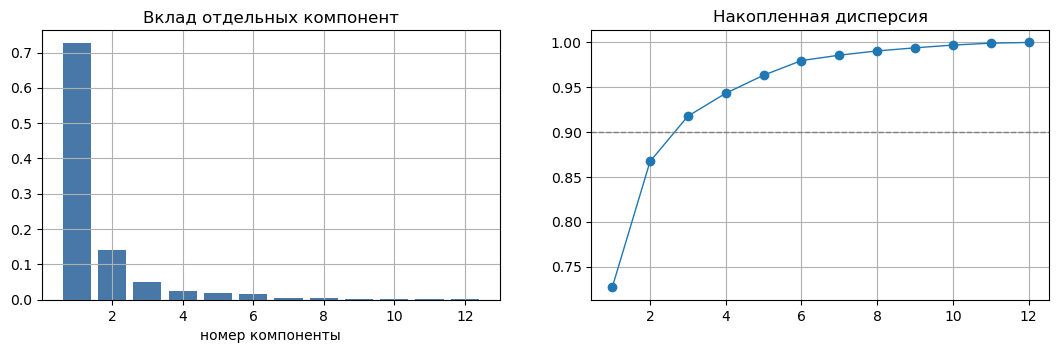

In [7]:
scaled_telemetry = StandardScaler().fit_transform(telemetry[active_columns].to_numpy())
pca = PCA(random_state=SEED).fit(scaled_telemetry)
cumulative = np.cumsum(pca.explained_variance_ratio_)
print("накопленная доля дисперсии:", np.round(cumulative[:8], 3))
print("для 90% дисперсии нужно компонент:", int(np.searchsorted(cumulative, 0.9) + 1),
      "| для 95%:", int(np.searchsorted(cumulative, 0.95) + 1))

fig, axes = plt.subplots(1, 2, figsize=(13, 3.5))
axes[0].bar(np.arange(1, len(cumulative) + 1), pca.explained_variance_ratio_, color="#4878a8")
axes[0].set_title("Вклад отдельных компонент")
axes[0].set_xlabel("номер компоненты")
axes[1].plot(np.arange(1, len(cumulative) + 1), cumulative, marker="o", linewidth=1)
axes[1].axhline(0.9, color="gray", linestyle="--", linewidth=1)
axes[1].set_title("Накопленная дисперсия")
plt.show()


Каналы сильно дублируют друг друга: три компоненты объясняют 91.8% дисперсии, пяти хватает для 95%. При этом в абляции ниже видно, что три главные компоненты дают практически тот же MAE, что и 12 исходных каналов (разница в четвёртом знаке). То есть сжатие допустимо, но выигрыша не даёт, а интерпретировать признаки вида «среднее за час по каналу 3» проще, чем «первая компонента», поэтому основные модели обучаю на исходных каналах.


### Синхронизация телеметрии и замеров

Результат анализа приходит через 10–15 минут после отбора пробы, поэтому замер с меткой времени `t` описывает состояние печи в момент `t - delay`. Именно на этот момент и подтягиваются признаки телеметрии.

Отдельно нужен признак «последний известный замер»: он берётся строго раньше момента прогноза (`direction="backward"`), поэтому подсматривания в будущее нет, а на реальном пульте такое значение действительно доступно.


### Выбор задержки

Точное время анализа в условии не задано, есть только интервал 10–15 минут. Поэтому задержку выбираю по данным: перебираю несколько значений и смотрю MAE на том же временном hold-out, на котором потом сравниваю модели. Перебор идёт на быстрой модели, чтобы не тратить время на полный цикл.

Минус такого подхода: раз задержка подбирается на той же валидации, её вклад в итоговую метрику немного оптимистичен. Разброс по сетке получается около 0.005 MAE, то есть задержка влияет, но не радикально; минимум попадает на 15 минут, что соответствует верхней границе заявленного интервала.

Нулевую задержку не проверяю: результат анализа не может быть известен в момент отбора пробы. Признак «последний замер» берётся строго раньше момента прогноза, поэтому собственный результат анализа в него не попадает.


In [8]:
def make_table(target, delay=None):
    delay = LAB_DELAY_MIN if delay is None else delay
    labels = target.rename(columns={"datetime": "lab_time"}).copy()
    labels["probe_time"] = labels["lab_time"] - pd.Timedelta(minutes=delay)
    rows = pd.merge_asof(
        labels.sort_values("probe_time"), features.sort_values("datetime"),
        left_on="probe_time", right_on="datetime", direction="backward",
        tolerance=pd.Timedelta("1min"),
    )
    known_labs = target_all.rename(columns={"datetime": "known_time", "target": "last_lab"})[["known_time", "last_lab"]]
    # строго более ранний замер: сдвиг на секунду не даёт подмешать сам текущий анализ
    rows["lookup_time"] = rows["probe_time"] - pd.Timedelta(seconds=1)
    rows = pd.merge_asof(
        rows.sort_values("lookup_time"), known_labs,
        left_on="lookup_time", right_on="known_time", direction="backward",
    )
    rows["hours_since_lab"] = (rows["probe_time"] - rows["known_time"]).dt.total_seconds() / 3600
    rows["last_lab"] = rows["last_lab"].fillna(target_train["target"].median())
    rows["hours_since_lab"] = rows["hours_since_lab"].fillna(72)

    # состояние каналов в момент последнего известного замера, чтобы посчитать дрейф
    rows = rows.reset_index(drop=True)
    rows["row_id"] = np.arange(len(rows))
    state = telemetry[["datetime"] + active_columns].rename(columns={"datetime": "known_time"})
    anchors = rows.loc[rows["known_time"].notna(), ["row_id", "known_time"]].sort_values("known_time")
    matched = pd.merge_asof(anchors, state.sort_values("known_time"), on="known_time", direction="backward")
    matched = matched.set_index("row_id")
    for col in active_columns:
        rows[f"{col}_drift"] = rows[col] - rows["row_id"].map(matched[col])
    return rows.drop(columns=["datetime", "row_id", "lookup_time"])

drift_columns = [f"{c}_drift" for c in active_columns]
model_columns = feature_columns + ["last_lab", "hours_since_lab"] + drift_columns
print("признаков в модели:", len(model_columns))


признаков в модели: 196


In [9]:
def valid_mae_for_delay(delay):
    table = make_table(target_train, delay).dropna(subset=model_columns)
    boundary = int(len(table) * 0.8)
    model = HistGradientBoostingRegressor(max_iter=250, learning_rate=0.05, random_state=SEED)
    model.fit(table[model_columns].iloc[:boundary], table["target"].iloc[:boundary] - table["last_lab"].iloc[:boundary])
    prediction = table["last_lab"].iloc[boundary:] + model.predict(table[model_columns].iloc[boundary:])
    return mean_absolute_error(table["target"].iloc[boundary:], prediction)

delay_scores = pd.Series({d: valid_mae_for_delay(d) for d in (6, 10, 12, 15, 20, 30)}, name="MAE")
delay_scores.index.name = "сдвиг, мин"
display(delay_scores.round(4).to_frame())
LAB_DELAY_MIN = int(delay_scores.idxmin())
print("выбрана задержка", LAB_DELAY_MIN, "мин, MAE =", round(delay_scores.min(), 4))

train_table = make_table(target_train).dropna(subset=model_columns).reset_index(drop=True)
test_table = make_table(target_test).dropna(subset=model_columns).reset_index(drop=True)
print("строк в train:", len(train_table), "| в test:", len(test_table))
display(train_table[["lab_time", "probe_time", "target", "last_lab", "hours_since_lab"]].head())


,MAE
"сдвиг, мин",
6,0.0580
10,0.0615
12,0.0587
15,0.0562
20,0.0564
30,0.0596


выбрана задержка 15 мин, MAE = 0.0562


строк в train: 1772 | в test: 318


,lab_time,probe_time,target,last_lab,hours_since_lab
0,2019-03-13 21:00:00,2019-03-13 20:45:00,0.319588,0.123711,3.75
1,2019-03-14 01:00:00,2019-03-14 00:45:00,0.255155,0.319588,3.75
2,2019-03-14 05:00:00,2019-03-14 04:45:00,0.319588,0.255155,3.75
3,2019-03-14 09:00:00,2019-03-14 08:45:00,0.159794,0.319588,3.75
4,2019-03-14 13:00:00,2019-03-14 12:45:00,0.368557,0.159794,3.75


## 3. Модели

**Как делю данные.** Замеры идут во времени, соседние значения очень близки, поэтому случайное разбиение дало бы завышенные метрики: почти у каждого объекта в валидации нашёлся бы почти такой же сосед в обучении. Беру первые 80% замеров на обучение и последние 20% на валидацию, а `test_small` трогаю только в самом конце, один раз.

**С чем сравниваю.** Две рабочие альтернативы без модели: постоянная медиана из обучения и «последний известный замер» (то, что оператор и так видит на пульте). Если модель не бьёт эти варианты, она бесполезна независимо от качества подгонки.

**Что за модели.**

* `Ridge` — линейная модель на нормированных признаках, коэффициент регуляризации подбирается внутри пайплайна через `RidgeCV` и `TimeSeriesSplit`, чтобы не настраивать его руками по валидации;
* `ExtraTrees` — нелинейность и взаимодействия признаков, устойчив к масштабу и к выбросам, которых в телеметрии хватает;
* `HistGradientBoosting` — бустинг, обычно сильнее на табличных данных, быстро обучается на сотнях тысяч строк.

Нейросети (LSTM, трансформеры) здесь не нужны: обучающих замеров меньше двух тысяч, а связь телеметрии с концентрацией слабая, поэтому глубокая модель переобучится и проиграет деревьям. KNN тоже не подходит: евклидово расстояние по каналам с разными единицами измерения и разными масштабами не имеет физического смысла.

**Что предсказывают модели.** Не концентрацию напрямую, а поправку к последнему лабораторному замеру: `target - last_lab`. Уровень процесса меняется медленно, абсолютный уровень удобнее взять из последнего анализа, а модель пусть объясняет отклонение. Прогноз уровня получается как `last_lab + поправка`. Так модель не тратит ёмкость на восстановление уровня и занимается только отклонением от него.

`ARIMA` обучается только на истории `target` без телеметрии: она нужна как эталон, показывающий, сколько даёт сама по себе временная структура ряда.


In [10]:
def wape(y_true, y_pred):
    return np.abs(y_true - y_pred).sum() / np.abs(y_true).sum()

def mape(y_true, y_pred):
    mask = y_true > 0.02
    return np.mean(np.abs((y_true[mask] - y_pred[mask]) / y_true[mask]))

def score(y_true, y_pred, reference):
    y_true, y_pred, reference = map(np.asarray, (y_true, y_pred, reference))
    return {
        "MAE": mean_absolute_error(y_true, y_pred),
        "RMSE": np.sqrt(mean_squared_error(y_true, y_pred)),
        "MAPE": mape(y_true, y_pred),
        "WAPE": wape(y_true, y_pred),
        "направление от замера": np.mean(np.sign(y_true - reference) == np.sign(y_pred - reference)),
        "направление шага": np.mean(np.sign(np.diff(y_true)) == np.sign(np.diff(y_pred))),
    }

boundary = int(len(train_table) * 0.8)
train_part = train_table.iloc[:boundary].reset_index(drop=True)
valid_part = train_table.iloc[boundary:].reset_index(drop=True)
print("обучение:", len(train_part), "замеров | валидация:", len(valid_part))

model_estimators = {
    "Ridge": make_pipeline(StandardScaler(), RidgeCV(alphas=np.logspace(0, 4, 9), cv=TimeSeriesSplit(4))),
    "ExtraTrees": ExtraTreesRegressor(n_estimators=300, min_samples_leaf=3, max_features=0.6,
                                      random_state=SEED, n_jobs=-1),
    "HistGradientBoosting": HistGradientBoostingRegressor(max_iter=400, learning_rate=0.05, max_leaf_nodes=31,
                                                          l2_regularization=1.0, random_state=SEED),
}

valid_scores = {}
valid_scores["Медиана train"] = score(valid_part["target"],
                                      np.full(len(valid_part), train_part["target"].median()),
                                      valid_part["last_lab"])
valid_scores["Последний замер"] = score(valid_part["target"], valid_part["last_lab"], valid_part["last_lab"])
valid_predictions = {}
for name, estimator in model_estimators.items():
    estimator.fit(train_part[model_columns], train_part["target"] - train_part["last_lab"])
    valid_predictions[name] = valid_part["last_lab"] + estimator.predict(valid_part[model_columns])
    valid_scores[name] = score(valid_part["target"], valid_predictions[name], valid_part["last_lab"])

valid_table = pd.DataFrame(valid_scores).T
display(valid_table.sort_values("MAE").round(4))
candidates = [n for n in valid_table.index if n in model_estimators]
best_name = valid_table.loc[candidates, "MAE"].idxmin()
print("лучшая модель на валидации:", best_name, "| MAE =", round(valid_table.loc[best_name, "MAE"], 4))


обучение: 1417 замеров | валидация: 355


,MAE,RMSE,MAPE,WAPE,направление от замера,направление шага
HistGradientBoosting,0.0564,0.0718,0.2868,0.2498,0.6676,0.4492
ExtraTrees,0.0569,0.0712,0.3024,0.2518,0.6535,0.4181
Ridge,0.0586,0.0733,0.3118,0.2592,0.6366,0.3729
Последний замер,0.0638,0.0822,0.3071,0.2826,0.0535,0.3503
Медиана train,0.0718,0.0860,0.4109,0.3180,0.5887,0.0537


лучшая модель на валидации: HistGradientBoosting | MAE = 0.0564


В таблице есть две тонкости.

* У строки «последний замер» точность направления около нуля не потому, что вариант плохой, а потому, что его прогноз в точности равен опорному значению: сравнивать два нуля бессмысленно, эта метрика для константы не определена.
* MAPE считается только по замерам с концентрацией выше 0.02: в данных есть значения около нуля, и относительная ошибка там формально уходит в бесконечность. Общей доле ошибки WAPE доверия больше.


### Абляция

Проверяю три набора признаков на одной и той же модели (`ExtraTrees`), чтобы понять, откуда берётся качество: только из истории лабораторных замеров, из телеметрии вместе с ней или из сжатой версии телеметрии через главные компоненты. Сравнение на одинаковой модели и одинаковом разбиении, поэтому разница в метриках относится именно к признакам.


In [11]:
def ablation_score(columns, train_frame, valid_frame):
    model = ExtraTreesRegressor(n_estimators=300, min_samples_leaf=3, max_features=0.6,
                                random_state=SEED, n_jobs=-1)
    model.fit(train_frame[columns], train_frame["target"] - train_frame["last_lab"])
    prediction = valid_frame["last_lab"] + model.predict(valid_frame[columns])
    result = score(valid_frame["target"], prediction, valid_frame["last_lab"])
    return {"MAE": result["MAE"], "RMSE": result["RMSE"], "направление от замера": result["направление от замера"]}

pca_snapshot = PCA(n_components=3, random_state=SEED).fit_transform(
    StandardScaler().fit_transform(telemetry[active_columns].to_numpy())
)
pca_frame = (pd.DataFrame(pca_snapshot, columns=["pc1", "pc2", "pc3"], index=telemetry["datetime"])
             .reset_index().rename(columns={"datetime": "probe_time"}).sort_values("probe_time"))

def attach_pca(part):
    merged = pd.merge_asof(part.sort_values("probe_time"), pca_frame, on="probe_time",
                           direction="backward", tolerance=pd.Timedelta("1min"))
    return merged.dropna(subset=["pc1", "pc2", "pc3"]).reset_index(drop=True)

train_pca, valid_pca = attach_pca(train_part), attach_pca(valid_part)
pca_columns = [c for c in model_columns if c not in active_columns] + ["pc1", "pc2", "pc3"]
lab_columns = ["last_lab", "hours_since_lab"]

ablation = {
    "только история замеров": ablation_score(lab_columns, train_part, valid_part),
    "телеметрия + история замеров": ablation_score(model_columns, train_part, valid_part),
    "PCA-3 вместо 12 каналов": ablation_score(pca_columns, train_pca, valid_pca),
}
ablation_table = pd.DataFrame(ablation).T
display(ablation_table.sort_values("MAE").round(4))
print("вклад телеметрии сверх истории замеров, MAE:",
      round(ablation_table.loc["только история замеров", "MAE"] - ablation_table.loc["телеметрия + история замеров", "MAE"], 4))


,MAE,RMSE,направление от замера
телеметрия + история замеров,0.0569,0.0712,0.6535
PCA-3 вместо 12 каналов,0.0570,0.0715,0.6394
только история замеров,0.0602,0.0773,0.6423


вклад телеметрии сверх истории замеров, MAE: 0.0033


In [12]:
y_fit = train_part["target"].to_numpy()
y_valid = valid_part["target"].to_numpy()

adf = adfuller(y_fit, autolag="AIC")
order_d = 0 if adf[1] < 0.05 else 1
print(f"ADF: статистика {adf[0]:.3f}, p-value {adf[1]:.4f} -> "
      f"{'ряд можно считать стационарным' if order_d == 0 else 'ряд нестационарен'}, d = {order_d}")

arima_grid = []
for p in range(4):
    for q in range(3):
        try:
            fitted = ARIMA(y_fit, order=(p, order_d, q), trend="c").fit()
        except Exception:
            continue
        arima_grid.append({"p": p, "q": q, "AIC": fitted.aic, "BIC": fitted.bic})
arima_grid = pd.DataFrame(arima_grid).sort_values("AIC").reset_index(drop=True)
display(arima_grid.head(8).round(1))

best_p, best_q = int(arima_grid.loc[0, "p"]), int(arima_grid.loc[0, "q"])
arima_model = ARIMA(y_fit, order=(best_p, order_d, best_q), trend="c").fit()
arima_prediction = arima_model.forecast(len(y_valid))
print(f"выбран порядок ARIMA({best_p}, {order_d}, {best_q}), AIC = {arima_model.aic:.1f}")

comparison = valid_table.copy()
comparison.loc["ARIMA (только target)"] = pd.Series(score(y_valid, arima_prediction, valid_part["last_lab"]))
display(comparison.sort_values("MAE").round(4))


ADF: статистика -5.219, p-value 0.0000 -> ряд можно считать стационарным, d = 0


,p,q,AIC,BIC
0,3,2,-3216.1,-3179.3
1,2,1,-3211.7,-3185.4
2,2,2,-3210.4,-3178.8
3,3,1,-3208.9,-3177.4
4,1,2,-3199.4,-3173.1
5,1,1,-3198.2,-3177.2
6,2,0,-3197.4,-3176.3
7,3,0,-3197.2,-3170.9


выбран порядок ARIMA(3, 0, 2), AIC = -3216.1


,MAE,RMSE,MAPE,WAPE,направление от замера,направление шага
HistGradientBoosting,0.0564,0.0718,0.2868,0.2498,0.6676,0.4492
ExtraTrees,0.0569,0.0712,0.3024,0.2518,0.6535,0.4181
Ridge,0.0586,0.0733,0.3118,0.2592,0.6366,0.3729
Последний замер,0.0638,0.0822,0.3071,0.2826,0.0535,0.3503
ARIMA (только target),0.0708,0.0847,0.4027,0.3134,0.6225,0.4463
Медиана train,0.0718,0.0860,0.4109,0.3180,0.5887,0.0537


## 4. Проверка качества

Смотрю на остатки лучшей модели: если в них осталась структура (автокорреляция, зависимость разброса от уровня), значит модель что-то систематически не учла, и метрики на валидации не стоит считать окончательными. Дополнительно считаю permutation importance — перемешивание признака и рост ошибки, это честная оценка вклада на отложенных данных, в отличие от встроенной важности деревьев, которая смещена в пользу признаков с большим числом уникальных значений.


средняя ошибка: -0.0018 | медиана |ошибки|: 0.0461 | стандартное отклонение: 0.0718
Shapiro-Wilk: W = 0.990, p = 0.0130


,lb_stat,lb_pvalue
10,13.3037,0.2072
20,31.2381,0.0521


Breusch-Pagan: LM = 7.82, p = 0.0052


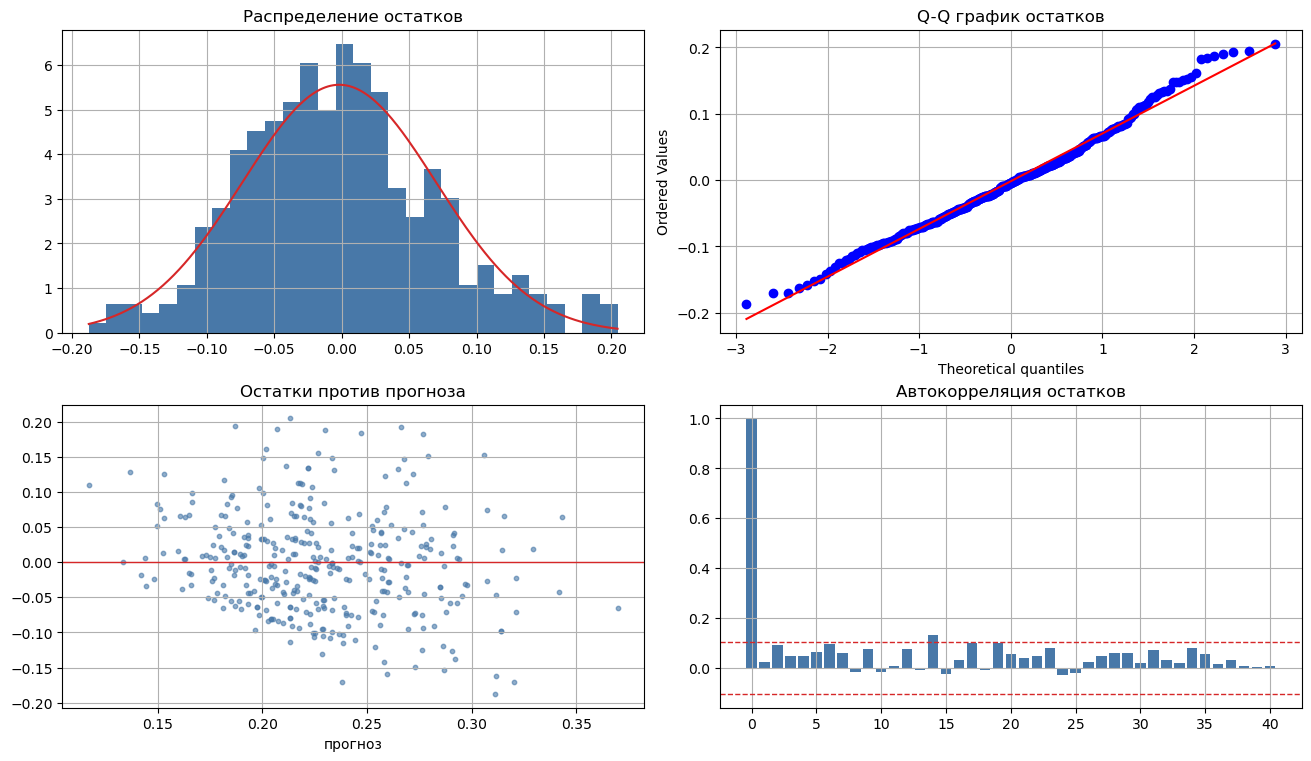

In [13]:
best_model = model_estimators[best_name]
best_prediction = np.asarray(valid_predictions[best_name])
residuals = valid_part["target"].to_numpy() - best_prediction

print("средняя ошибка:", round(residuals.mean(), 4),
      "| медиана |ошибки|:", round(np.median(np.abs(residuals)), 4),
      "| стандартное отклонение:", round(residuals.std(), 4))
shapiro = stats.shapiro(residuals)
print(f"Shapiro-Wilk: W = {shapiro.statistic:.3f}, p = {shapiro.pvalue:.4f}")
display(acorr_ljungbox(residuals, lags=[10, 20], return_df=True).round(4))
breusch_pagan = het_breuschpagan(residuals, np.column_stack([np.ones_like(residuals), best_prediction]))
print(f"Breusch-Pagan: LM = {breusch_pagan[0]:.2f}, p = {breusch_pagan[1]:.4f}")

fig, axes = plt.subplots(2, 2, figsize=(13, 7.5), constrained_layout=True)
axes[0, 0].hist(residuals, bins=30, density=True, color="#4878a8")
grid = np.linspace(residuals.min(), residuals.max(), 200)
axes[0, 0].plot(grid, stats.norm.pdf(grid, residuals.mean(), residuals.std()), color="tab:red")
axes[0, 0].set_title("Распределение остатков")
stats.probplot(residuals, dist="norm", plot=axes[0, 1])
axes[0, 1].set_title("Q-Q график остатков")
axes[1, 0].scatter(best_prediction, residuals, s=10, alpha=0.6, color="#4878a8")
axes[1, 0].axhline(0, color="tab:red", linewidth=1)
axes[1, 0].set_title("Остатки против прогноза")
axes[1, 0].set_xlabel("прогноз")
residual_acf = acf(residuals, nlags=40, fft=False)
axes[1, 1].bar(np.arange(len(residual_acf)), residual_acf, color="#4878a8")
axes[1, 1].axhline(1.96 / np.sqrt(len(residuals)), color="tab:red", linestyle="--", linewidth=1)
axes[1, 1].axhline(-1.96 / np.sqrt(len(residuals)), color="tab:red", linestyle="--", linewidth=1)
axes[1, 1].set_title("Автокорреляция остатков")
plt.show()


,прирост MAE
last_lab,0.02055
telemetry_0_drift,0.00039
telemetry_10_std15,0.00032
telemetry_2_lag60,0.00027
telemetry_11_std60,0.00024
telemetry_1_drift,0.00023
telemetry_5_lag60,0.00022
telemetry_1_std60,0.00022
telemetry_5_std60,0.00021
telemetry_3_mean240,0.00018


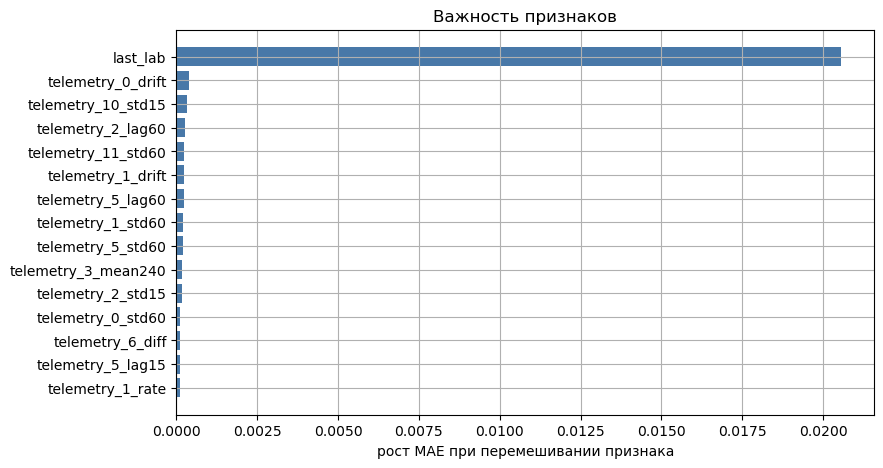

топ-5: last_lab, telemetry_0_drift, telemetry_10_std15, telemetry_2_lag60, telemetry_11_std60


In [14]:
importance = permutation_importance(
    best_model, valid_part[model_columns], valid_part["target"] - valid_part["last_lab"],
    n_repeats=8, random_state=SEED, scoring="neg_mean_absolute_error", n_jobs=-1,
)
importance_table = pd.Series(importance.importances_mean, index=model_columns).sort_values(ascending=False)
display(importance_table.head(15).round(5).to_frame("прирост MAE"))

fig, ax = plt.subplots(figsize=(9, 5))
top_features = importance_table.head(15)[::-1]
ax.barh(top_features.index, top_features.values, color="#4878a8")
ax.set_xlabel("рост MAE при перемешивании признака")
ax.set_title("Важность признаков")
plt.show()
print("топ-5:", ", ".join(importance_table.head(5).index))


,валидация (последние 20% train),test_small
MAE,0.0564,0.0509
RMSE,0.0718,0.0671
MAPE,0.2868,0.2701
WAPE,0.2498,0.2426
направление от замера,0.6676,0.6541
направление шага,0.4492,0.4290


baseline «последний замер» на test, MAE: 0.0595


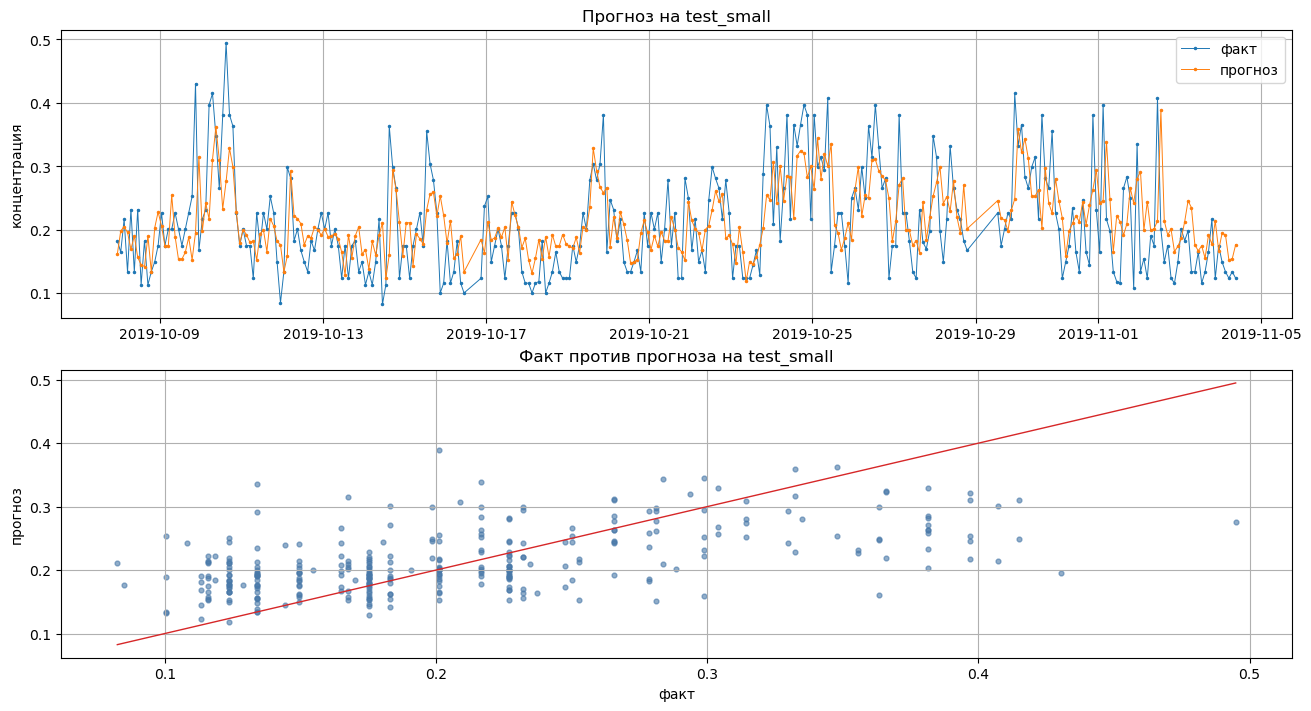

MAE 0.0509 при среднем уровне 0.210, то есть WAPE 24.3%


In [15]:
final_model = clone(best_model)
final_model.fit(train_table[model_columns], train_table["target"] - train_table["last_lab"])
test_prediction = test_table["last_lab"].to_numpy() + final_model.predict(test_table[model_columns])
test_scores = score(test_table["target"].to_numpy(), test_prediction, test_table["last_lab"])

summary = pd.DataFrame({
    "валидация (последние 20% train)": pd.Series(valid_table.loc[best_name]),
    "test_small": pd.Series(test_scores),
})
display(summary.round(4))
print("baseline «последний замер» на test, MAE:",
      round(mean_absolute_error(test_table["target"], test_table["last_lab"]), 4))

fig, axes = plt.subplots(2, 1, figsize=(13, 7), constrained_layout=True)
axes[0].plot(test_table["lab_time"], test_table["target"].to_numpy(), marker=".", markersize=3,
             linewidth=0.7, label="факт")
axes[0].plot(test_table["lab_time"], test_prediction, marker=".", markersize=3,
             linewidth=0.7, label="прогноз")
axes[0].set_title("Прогноз на test_small")
axes[0].set_ylabel("концентрация")
axes[0].legend()
axes[1].scatter(test_table["target"], test_prediction, s=12, alpha=0.6, color="#4878a8")
limits = [test_table["target"].min(), test_table["target"].max()]
axes[1].plot(limits, limits, color="tab:red", linewidth=1)
axes[1].set_xlabel("факт")
axes[1].set_ylabel("прогноз")
axes[1].set_title("Факт против прогноза на test_small")
plt.show()
print(f"MAE {test_scores['MAE']:.4f} при среднем уровне {test_table['target'].mean():.3f},"
      f" то есть WAPE {test_scores['WAPE']:.1%}")


## 5. Выводы

* Данные пришлось привести в рабочий вид: 4 из 16 каналов практически пустые и отброшены, пропуски в остальных закрываются последним значением не глубже 15 минут. Около 20% точек формально попадают в выбросы по правилу 3·IQR, но это значения на границах шкалы 0–1, то есть рабочие режимы, а не сбои, поэтому чистка не применялась.
* Лабораторные замеры идут неравномерно: медианный интервал 2 часа, максимальный разрыв — 18 суток. Отсюда две отдельные задачи: синхронизация с задержкой анализа и перенос информации с редких замеров на минутную сетку. Задержка в условии задана интервалом 10–15 минут, перебор по данным даёт минимум на 15 минутах при разбросе около 0.005 MAE по сетке, поэтому в пайплайне используется она.
* Мгновенные значения каналов почти бесполезны: корреляция с концентрацией не превышает 0.19 по модулю и при сдвиге каналов на 10–60 минут почти не растёт. Работают производные признаки — лаги, скользящие средние и разброс, скорости изменения.
* Лучшая модель на валидации — `HistGradientBoosting` на поправке к последнему замеру: MAE 0.0564 против 0.0638 у «последнего замера» и 0.0718 у медианы, то есть на 12% и 21% лучше соответственно. `ExtraTrees` практически не отстаёт (0.0569), линейная модель хуже (0.0586), ARIMA по одной истории `target` проигрывает даже константе из train (0.0708). На `test_small` результат сохраняется: MAE 0.0509 при ошибке «последнего замера» 0.0595, WAPE 24.3%.
* Абляция показывает, откуда берётся качество: без телеметрии, только на истории замеров, MAE 0.0602, с телеметрией — 0.0569 (на `ExtraTrees`, чтобы менялся только набор признаков). Выигрыш от 196 признаков скромный, около 0.003, и основная часть точности приходит из последнего лабораторного замера: permutation importance ставит `last_lab` далеко впереди остальных признаков (0.021 против 0.0004 у следующего). На этих данных виртуальный датчик работает прежде всего как интерполяция между анализами, а телеметрия только подправляет её.
* Сжатие каналов через PCA не помогает: три компоненты объясняют 91.8% дисперсии и дают MAE 0.0570 против 0.0569 на 12 исходных каналах, то есть разницы нет. Поэтому оставлены исходные признаки, которые хотя бы интерпретируются.
* Остатки почти не смещены (средняя ошибка −0.0018), но белым шумом их считать нельзя: Shapiro-Wilk p = 0.013, Ljung-Box на 10 лагах p = 0.21, на 20 — p = 0.052, Breusch-Pagan p = 0.005. То есть явной автокорреляции не видно, зато разброс ошибки растёт вместе с уровнем, и строить доверительные интервалы по нормальному приближению нельзя.
* Главное ограничение работы: задержка выбиралась на том же отрезке, который использовался как валидация, а `test_small` — короткий месяц, поэтому итоговые метрики немного оптимистичны. Для промышленного применения задержку нужно брать из журнала отбора проб, а не подбирать по ошибке.

Что имеет смысл сделать дальше: добавить уставки и положения регуляторов (сейчас в телеметрии только измеряемые величины), ввести асимметричный штраф за ошибку в опасную сторону вместо MAE, проверить модель на периоде со сменой режима печи и объединить её с оценкой неопределённости по остаткам.
